Customer Churn Prediction 

In [2]:
#step - 1
#Standard imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Sklearn imports
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#Model imports
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

#Metrics imports & utilities
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import joblib 
import warnings
warnings.filterwarnings('ignore')

#Display settings
sns.set_theme(style="whitegrid", palette = "muted", font_scale = 1.05)
pd.set_option('display.max_columns', 200)




In [ ]:
#step - 2 Load the data

In [4]:
# Load the datasheet
df = pd.read_csv("Churn_Modelling.csv")
print("Shape :", df.shape)
df.head()

Shape : (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Step 3. Intial inspection 

In [5]:
# Info and Summary
display(df.info())
display(df.describe(include='all').T)

#Missing values
print("\nMissing Values :per column: ")
print(df.isnull().sum())

# Target distribution
print("\nChurn value counts: ")
print(df['Exited'].value_counts(normalize=False))
print("\nChurn proportion: ")
print(df['Exited'].value_counts(normalize=True))

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0



Missing Values :per column: 
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Churn value counts: 
Exited
0    7963
1    2037
Name: count, dtype: int64

Churn proportion: 
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


Step 4. Exploratory Data Analysis(visualisation)
we will look at distributions of numeric features, relationships with churn and categorized features

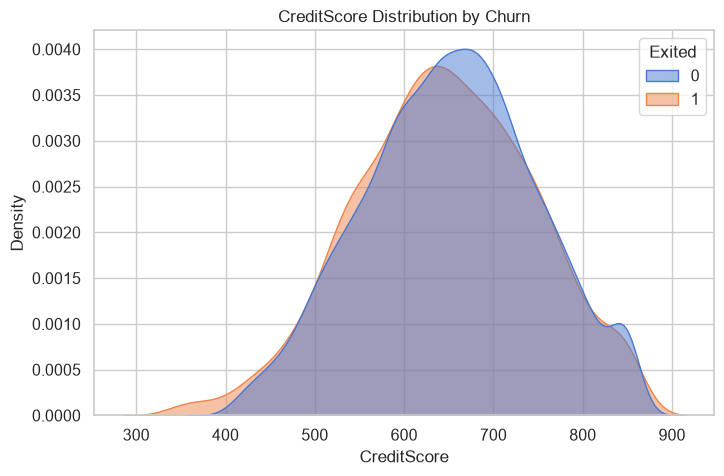

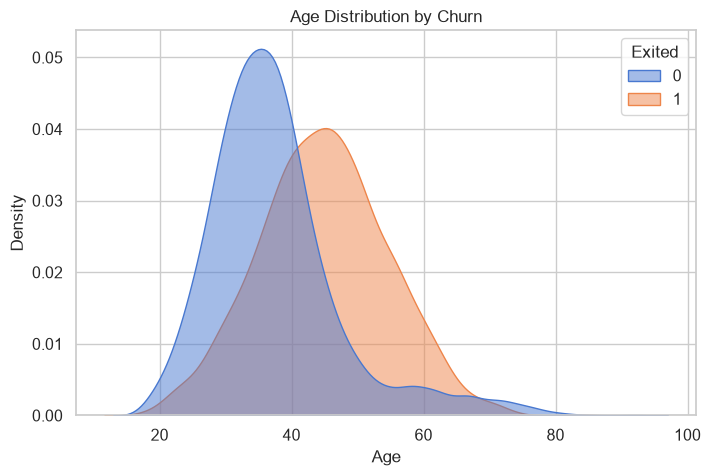

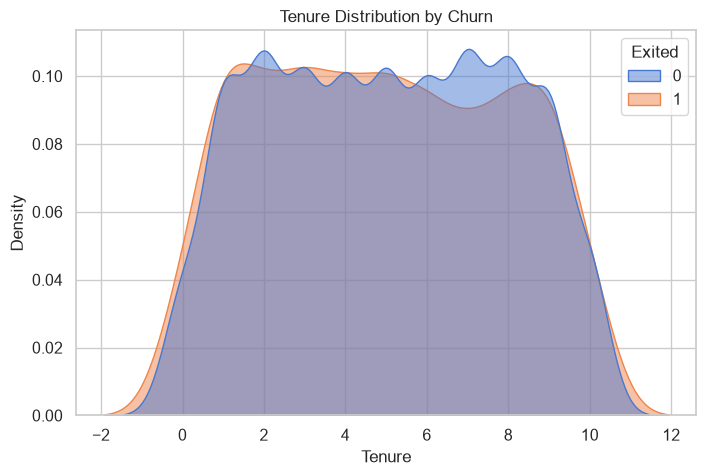

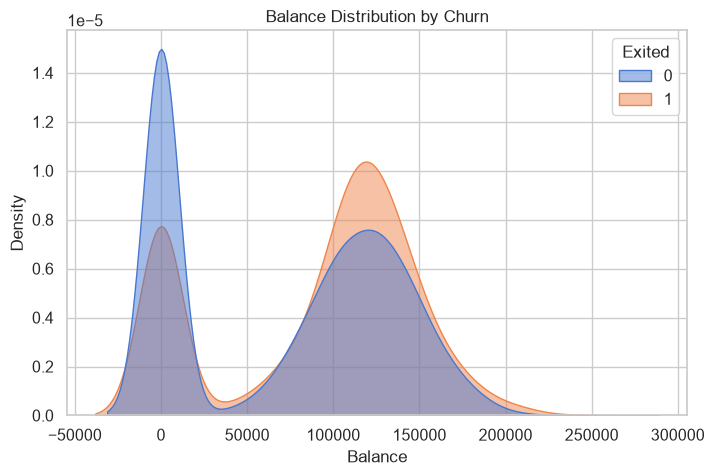

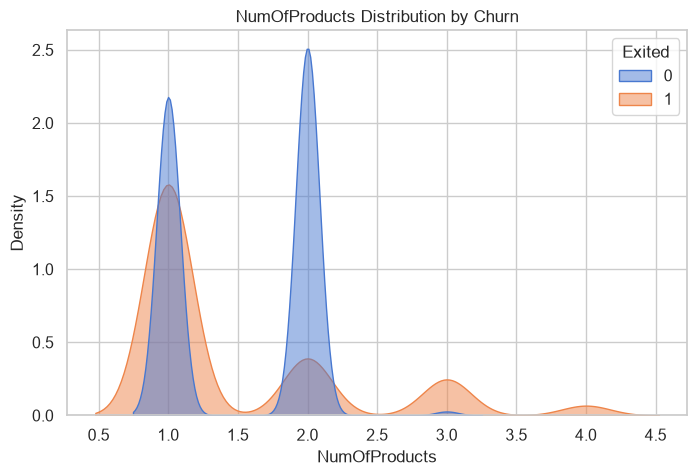

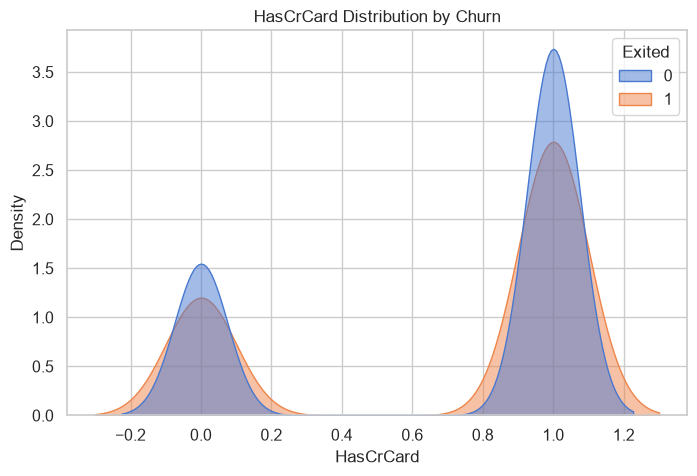

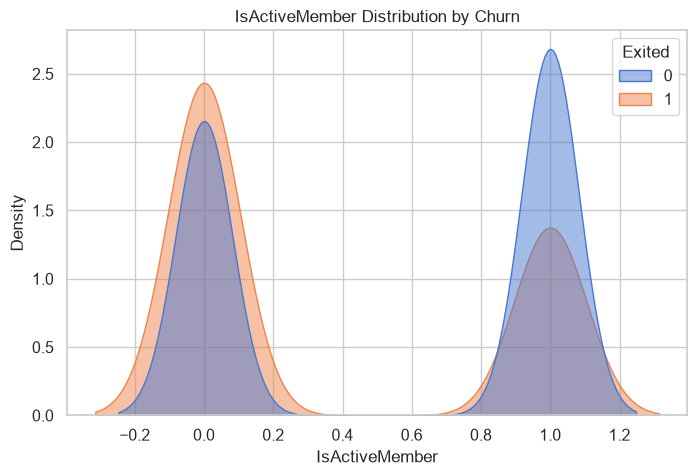

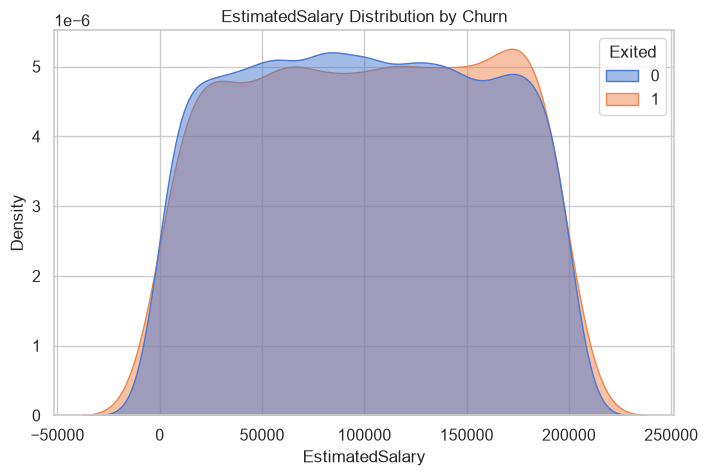

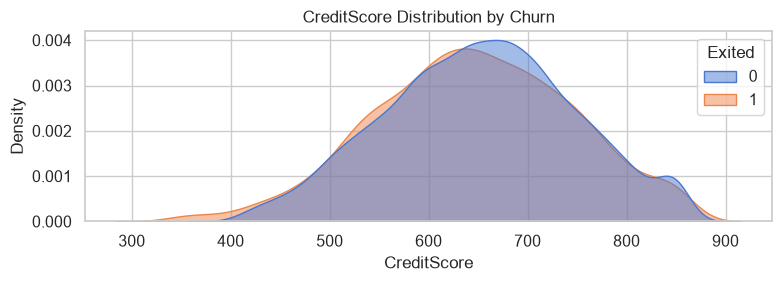

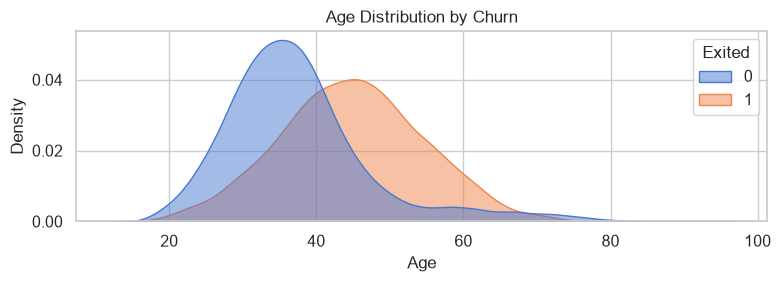

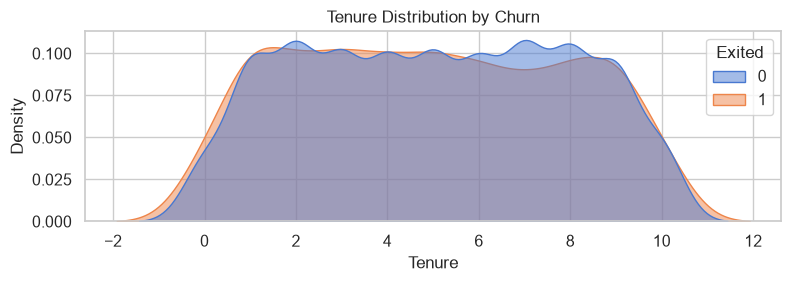

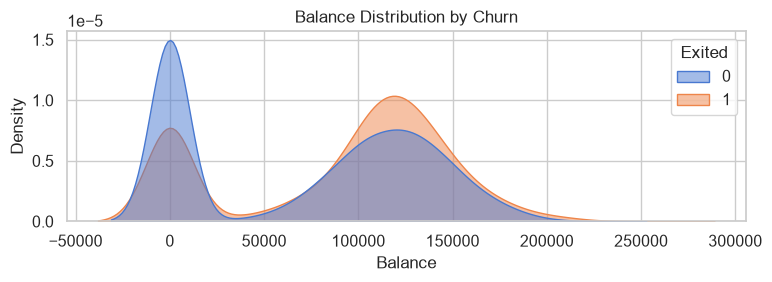

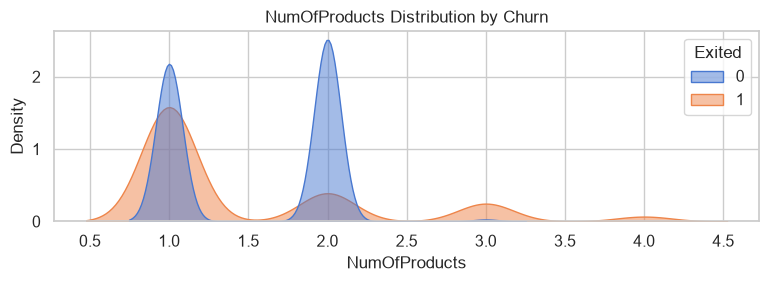

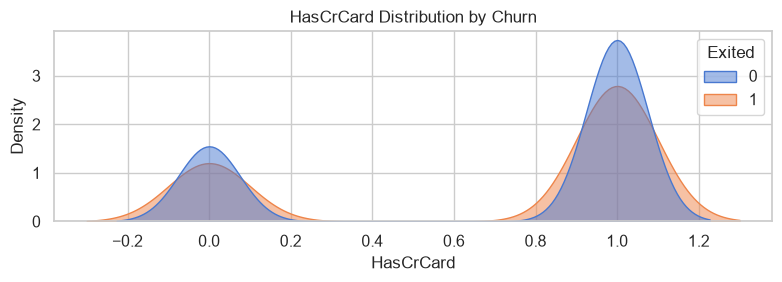

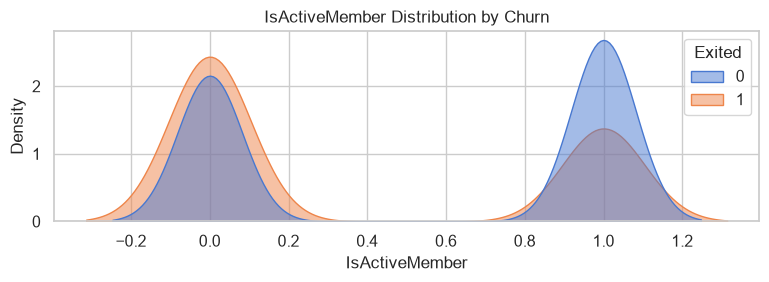

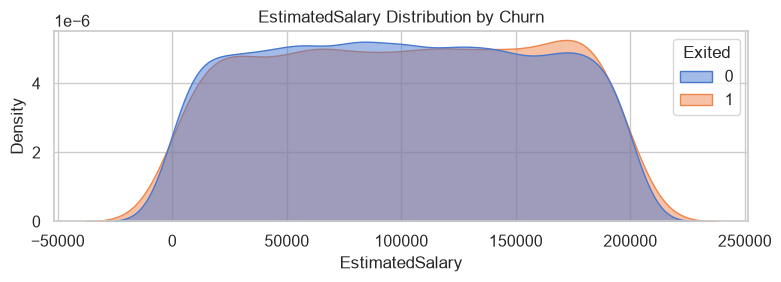

In [6]:
num_cols = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'HasCrCard',
    'IsActiveMember',
    'EstimatedSalary'
]

for col in num_cols:
    plt.figure(figsize=(8, 5))
    
    sns.kdeplot(
        data=df,
        x=col,
        hue='Exited',
        fill=True,
        common_norm=False,
        alpha=0.5
    )
    
    plt.title(f'{col} Distribution by Churn')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.show()
#.... Distribution plots
for col in num_cols:
    plt.figure(figsize=(8,3))
    sns.kdeplot(data=df, x=col, hue='Exited', fill=True, common_norm=False, alpha=0.5)
    plt.title(f'{col} Distribution by Churn')
    plt.tight_layout()
    plt.show()

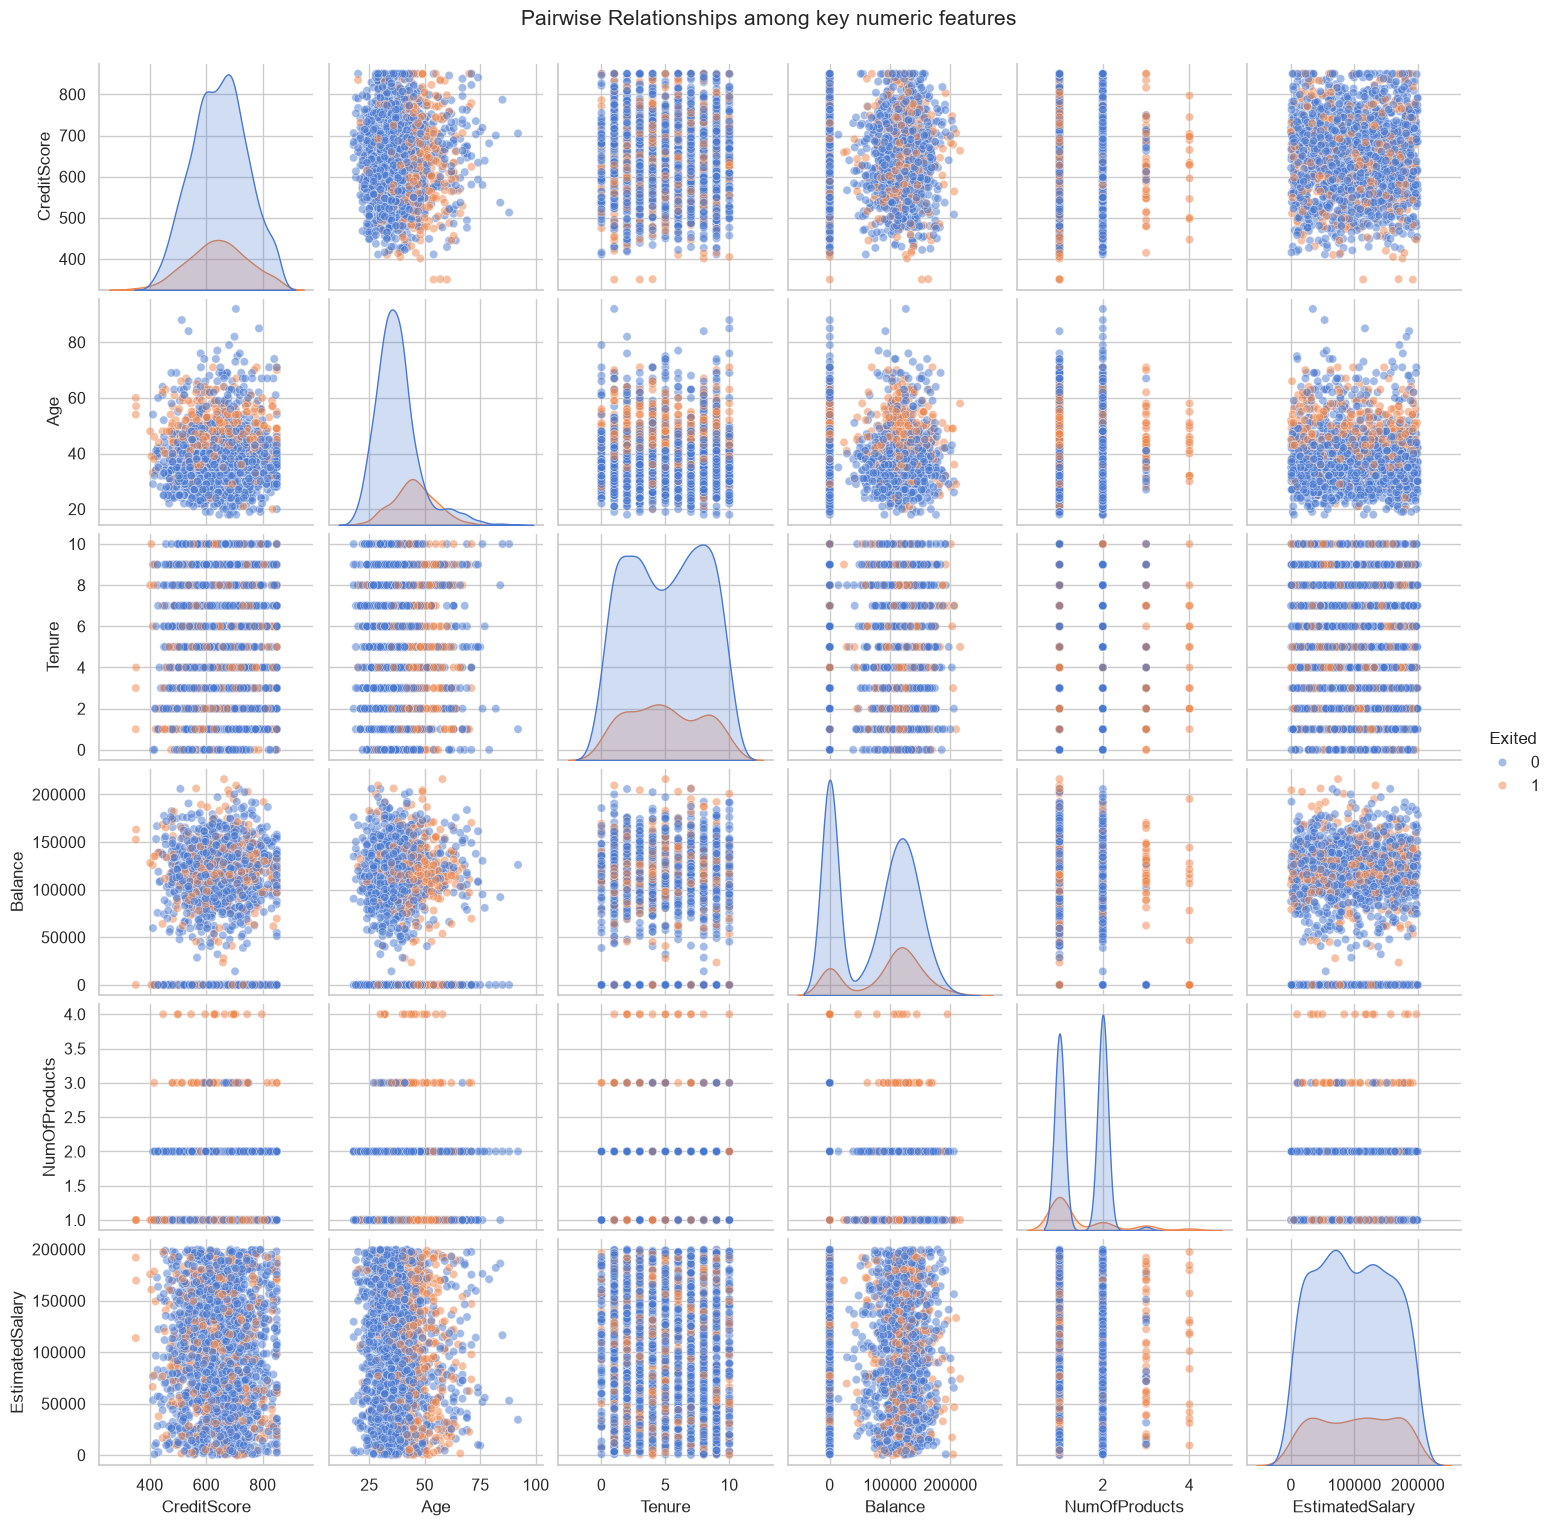

In [7]:
#---- Pairplot (sampled for speed)

sns.pairplot(df.sample(frac=0.2, random_state=42),
             vars=['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary'],
             hue='Exited', diag_kind='kde', plot_kws={'alpha':0.5})
plt.suptitle('Pairwise Relationships among key numeric features', y=1.02)
plt.show()

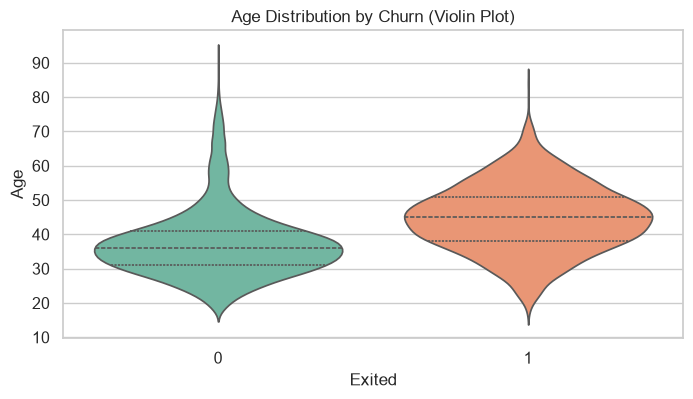

In [8]:
# ---- Violin plot for age
plt.figure(figsize=(8,4))
sns.violinplot(data=df, x='Exited', y='Age', palette='Set2', inner='quart')
plt.title('Age Distribution by Churn (Violin Plot)')
plt.show()

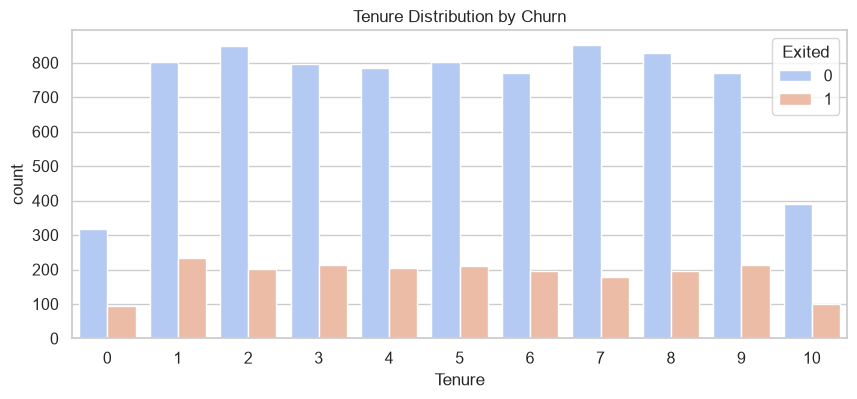

In [9]:
# ---- Tenure distribution
plt.figure(figsize=(10,4))
sns.countplot(data=df, x='Tenure', hue='Exited', palette='coolwarm')
plt.title('Tenure Distribution by Churn')
plt.show()

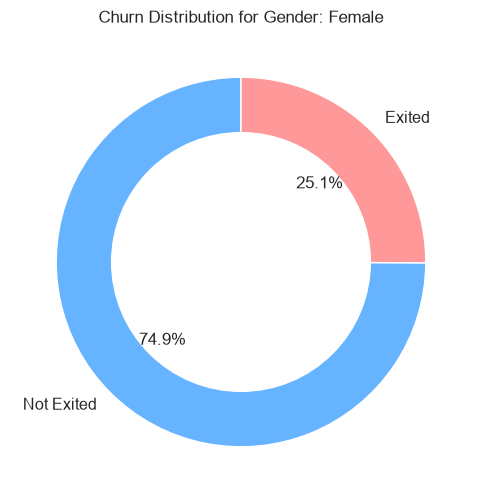

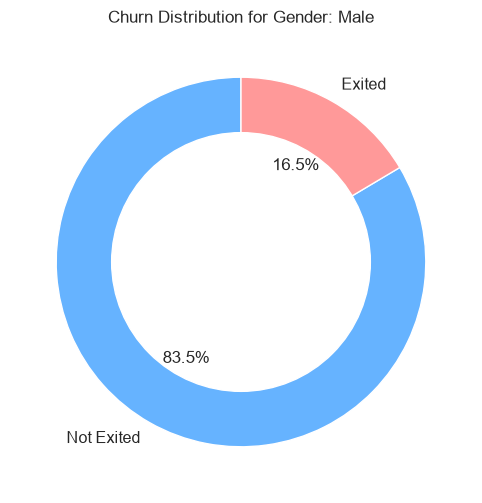

In [10]:
# ---- Gender vs churn Donut Chart 
gender_counts = df.groupby('Gender')['Exited'].value_counts(normalize=True).unstack().fillna(0)
for gender in gender_counts.index :
    plt.figure(figsize=(6,6))
    plt.pie(gender_counts.loc[gender], labels=['Not Exited', 'Exited'], autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#ff9999'])
    centre_circle = plt.Circle((0,0),0.70,fc='white')
    fig = plt.gcf()
    fig.gca().add_artist(centre_circle)
    plt.title(f'Churn Distribution for Gender: {gender}')
    plt.show()
    

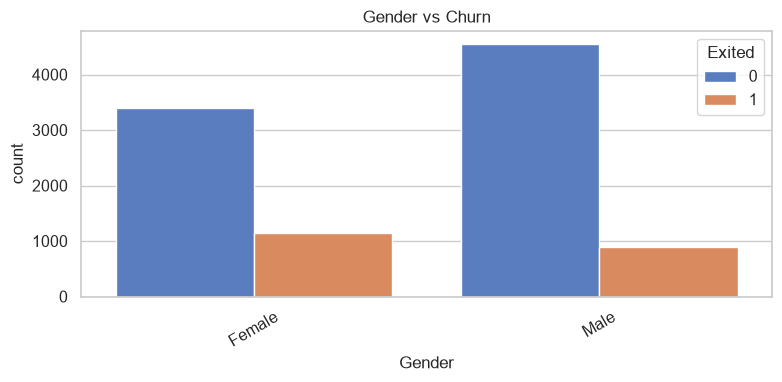

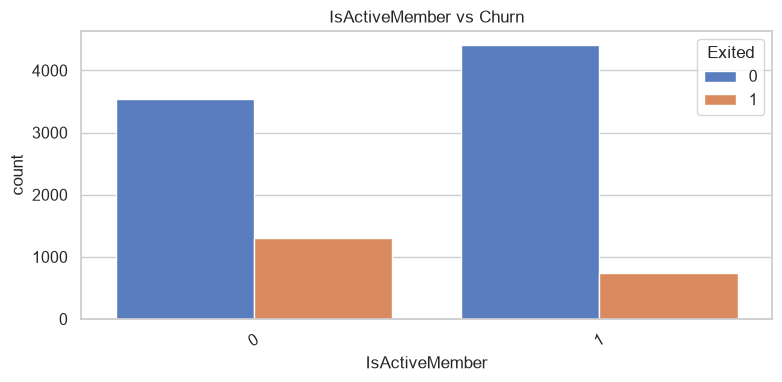

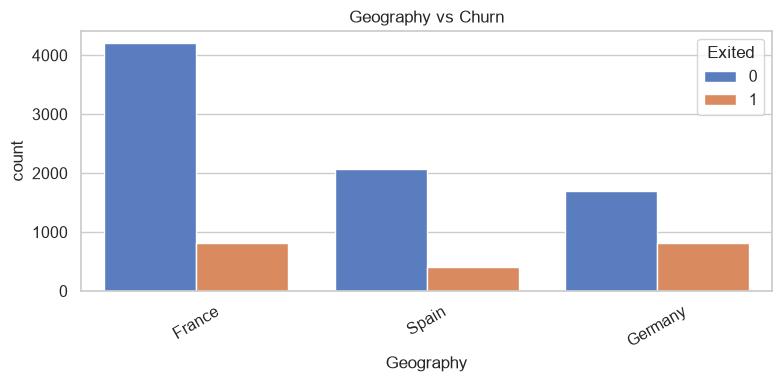

In [11]:
#---- Categorical features
categorical_cols = [ 'Gender',  'IsActiveMember', 'Geography']
for col in categorical_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=col, hue='Exited')
    plt.title(f'{col} vs Churn')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

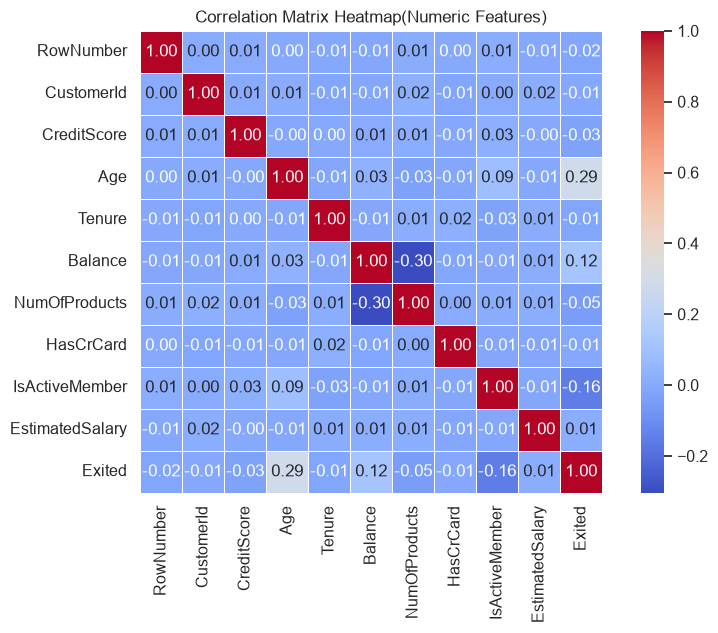

In [12]:
# ---- Heatmap of correlation matrix
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap='coolwarm', cbar=True, linewidths=0.5, square=True)
plt.title('Correlation Matrix Heatmap(Numeric Features)')
plt.show()

In [13]:
# --- Numeric Corelation heatmap
numeric_data = df[num_cols] # use the numeric columns from the feature-engineered dataframe
corr = numeric_data.corr()
corr.style.background_gradient(cmap='coolwarm')

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
CreditScore,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.005458,0.025651,-0.001384
Age,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.011721,0.085472,-0.007201
Tenure,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.022583,-0.028362,0.007784
Balance,0.006268,0.028308,-0.012254,1.000000,-0.304180,-0.014858,-0.010084,0.012797
NumOfProducts,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.003183,0.009612,0.014204
HasCrCard,-0.005458,-0.011721,0.022583,-0.014858,0.003183,1.000000,-0.011866,-0.009933
IsActiveMember,0.025651,0.085472,-0.028362,-0.010084,0.009612,-0.011866,1.000000,-0.011421
EstimatedSalary,-0.001384,-0.007201,0.007784,0.012797,0.014204,-0.009933,-0.011421,1.000000


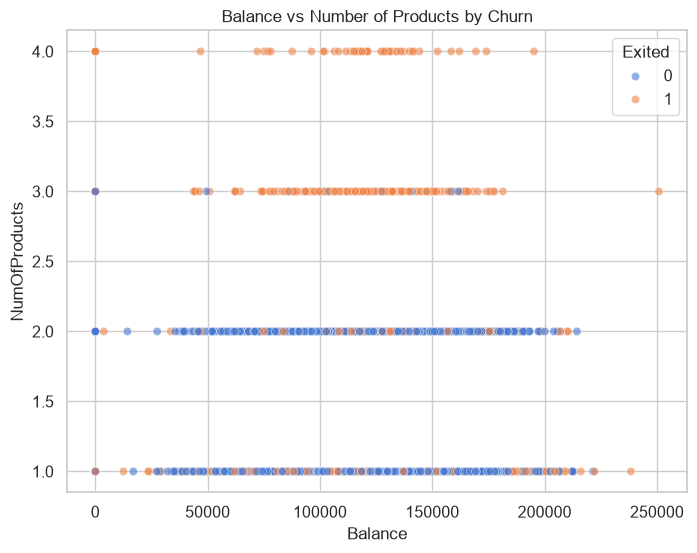

In [15]:
# ---- Balance vs Products scatter
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='Balance', y='NumOfProducts', hue='Exited', alpha=0.6)
plt.title('Balance vs Number of Products by Churn')
plt.show()

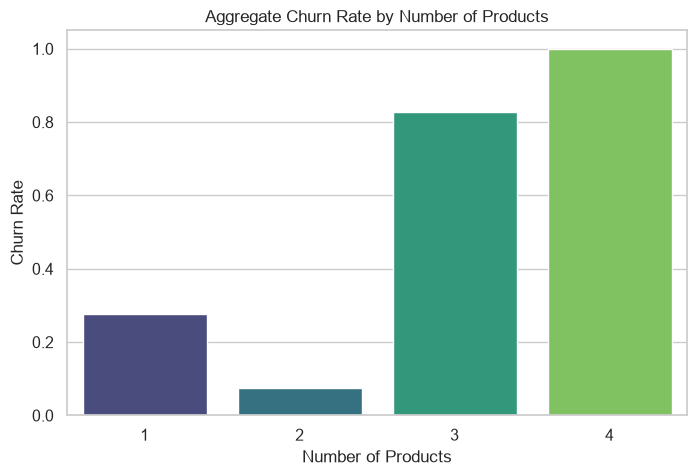

In [16]:
# --- Aggregate churnn rate per number of products
churn_rate = df.groupby('NumOfProducts')['Exited'].mean().reset_index()

#Plot churn rate
plt.figure(figsize=(8,5))
sns.barplot(data = churn_rate, x='NumOfProducts', y='Exited', palette='viridis')
plt.xlabel('Number of Products')
plt.ylabel('Churn Rate')
plt.title('Aggregate Churn Rate by Number of Products')
plt.show()

Step 5. Feature engineering 
Create meaningful features: e.g balance per product, age group, salary bracket and handle missing values

In [17]:
# Feature engineering example
df_fe = df.copy()

#Balance per producct
df_fe['BalancePerProduct'] = df_fe['Balance'] / (df_fe['NumOfProducts'] + 1e-5)  # Adding a small value to avoid division by zero
df_fe['BalancePerProduct'].fillna(0, inplace=True)  # Fill NaN values with 0 if any

#Salary to balance ratio
df_fe['SalaryToBalanceRatio'] = df_fe['EstimatedSalary'] / (df_fe['Balance'] + 1e-5)  # Adding a small value to avoid division by zero
df_fe['SalaryToBalanceRatio'].replace([np.inf, -np.inf],np.nan, inplace=True)  # Replace infinite values with 0
df_fe['SalaryToBalanceRatio'].fillna(df_fe['SalaryToBalanceRatio'].median(), inplace=True)  # Fill NaN values with median

# Age groups
bins = [0,25, 35, 45, 55, 65, 100]
labels = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']
df_fe['AgeGroup'] = pd.cut(df_fe['Age'], bins=bins, labels=labels)

# Tenure bucket
df_fe['tenure_bucket'] = pd.cut(df_fe['Tenure'], bins=[-1, 2, 5, 10], labels=['0-2', '3-5', '6-10'])

# Flag high balance
df_fe['HighBalanceFlag'] = (df_fe['Balance'] > 100000).astype(int)

# Quick checks
df_fe[[ 'BalancePerProduct', 'SalaryToBalanceRatio', 'AgeGroup', 'tenure_bucket', 'HighBalanceFlag']].head()

,BalancePerProduct,SalaryToBalanceRatio,AgeGroup,tenure_bucket,HighBalanceFlag
0,0.000000,1.013489e+10,35-44,0-2,0
1,83807.021930,1.342864e+00,35-44,0-2,0
2,53220.089266,7.135851e-01,35-44,6-10,1
3,0.000000,9.382663e+09,35-44,0-2,0
4,125509.564904,6.300979e-01,35-44,0-2,1


Step 6. Preprocessing - encoding and scaling 

In [ ]:
# Here is a preprocessing pipeline that encodes categorical features, scales numeric features, and handles missing values. This pipeline can be used to prepare the data for machine learning models.

In [18]:
# Define features and target
target = 'Exited'
drop_cols = ['CustomerId'] # Drop the 'CustomerId' column as it is not a useful feature
features = [col for col in df_fe.columns if col not in [target] + drop_cols]  # All columns except the target and dropped columns

numeric_features = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'NumOfProducts', 'SalaryToBalanceRatio', 'Tenure']

categorical_features = ['Gender', 'Geography', 'AgeGroup', 'tenure_bucket', 'HighBalanceFlag']  

df_fe[categorical_features] = df_fe[categorical_features].astype('object')  # Convert categorical features to 'category' dtype

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Impute missing values with most frequent value
    ('scaler', StandardScaler())  # Scale numeric features
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Impute missing values with most frequent value
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))  # One-hot encode categorical features
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

Numeric features: ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'NumOfProducts', 'SalaryToBalanceRatio', 'Tenure']
Categorical features: ['Gender', 'Geography', 'AgeGroup', 'tenure_bucket', 'HighBalanceFlag']


Step 7. Train Test split


In [19]:
x = df_fe[features]
y = df_fe[target]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(f'Training set shape: {x_train.shape}, Testing set shape: {x_test.shape}')
print('Train churn proportion:', y_train.mean(), 'Test churn proportion:', y_test.mean())


Training set shape: (8000, 17), Testing set shape: (2000, 17)
Train churn proportion: 0.20375 Test churn proportion: 0.2035


Step 8. Train Multiple models with a pipeline and compare using cross-validation

In [21]:
models = {

    'LogisticRegression': LogisticRegression(
        max_iter=500,
        random_state=42
    ),

    'RandomForest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    'GradientBoosting': GradientBoostingClassifier(
        n_estimators=200,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=200,
        random_state=42
    ),

    'SVC': SVC(
        probability=True,
        random_state=42
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42 )

results = {}
for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', model)
        ]
    )
    scores = cross_val_score(pipeline, x_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    results[name] = scores
    print(f"{name} AUC: Mean={scores.mean():.4f} Std={scores.std():.4f}")

    


LogisticRegression AUC: Mean=0.7742 Std=0.0215
RandomForest AUC: Mean=0.8319 Std=0.0125
GradientBoosting AUC: Mean=0.8499 Std=0.0110
AdaBoost AUC: Mean=0.8325 Std=0.0127
SVC AUC: Mean=0.8194 Std=0.0118


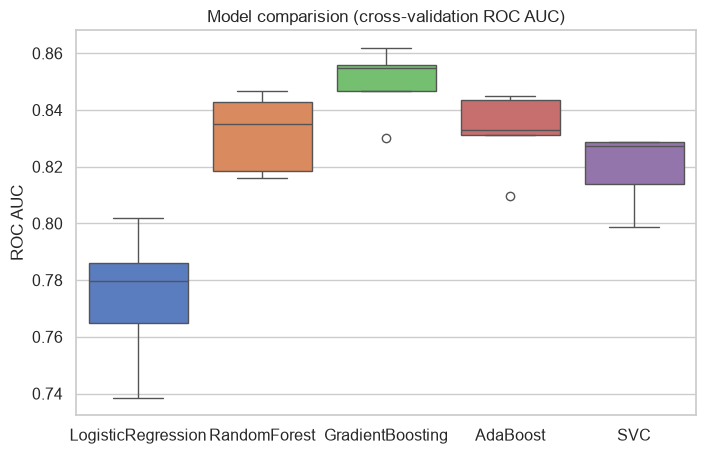

In [22]:
#Boxplot of CV AUC scores
plt.figure(figsize=(8,5))
sns.boxplot(data=[results [m] for m in list(results.keys())])
plt.xticks(ticks=range(len(results)), labels = list(results.keys()))
plt.ylabel('ROC AUC')
plt.title('Model comparision (cross-validation ROC AUC)')
plt.show()

#Step 9. Fit the best model on full train set and evaluate on test set
Select best model by mean CV AUC above and evalutes standard metrics on the test set

In [24]:
# Choose best model (automatic pick by mean AUC)
best_name = max(results.keys(), key=lambda k: results[k].mean())
best_name, results[best_name].mean()


('GradientBoosting', np.float64(0.8498829829241747))

Test Accuracy: 0.8530
Test Precision : 0.7233
Test Recall : 0.4496
Test F1-score: 0.5545
Test ROC AUC: 0.8535

Classification Report: 
              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1593
           1       0.72      0.45      0.55       407

    accuracy                           0.85      2000
   macro avg       0.80      0.70      0.73      2000
weighted avg       0.84      0.85      0.84      2000



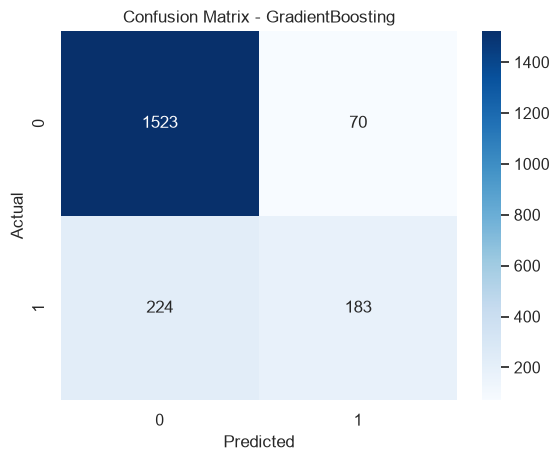

In [25]:
best_model = models[best_name]
best_pipeline = Pipeline(steps=[('preprocessor',preprocessor),
                                ('classifier',best_model)])
best_pipeline.fit(x_train, y_train)

#Prediction
y_pred = best_pipeline.predict(x_test)
y_proba = best_pipeline.predict_proba(x_test)[:,1]

# Metrics
acc = accuracy_score(y_test,y_pred)
prec = precision_score(y_test,y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test,y_pred)
roc = roc_auc_score(y_test, y_proba)

print(f"Test Accuracy: {acc:.4f}")
print(f"Test Precision : {prec:.4f}")
print(f"Test Recall : {rec:.4f}")
print(f"Test F1-score: {f1:.4f}")
print(f"Test ROC AUC: {roc:.4f}")

print("\nClassification Report: ")
print(classification_report(y_test,y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_name}')
plt.show()

Step 10. Feature importance(if applicable)

In [ ]:
# if the chossen model supports feature importance(RandomForest/GradientBoosting), show top features

In [ ]:
if hasattr(best_pipeline.named_steps['classifier'], 'feature_importances_'):

    num_feats = numeric_features

    cat_feats = list(
        best_pipeline
        .named_steps['preprocessor']
        .transformers_[1][1]
        .named_steps['onehot']
        .get_feature_names_out(categorical_features)
    )

    feature_names = num_feats + cat_feats

    importances = best_pipeline.named_steps['classifier'].feature_importances_

    fi = pd.Series(
        importances,
        index=feature_names
    ).sort_values(ascending=False)[:20]

    display(fi)

    plt.figure(figsize=(8, 6))

    sns.barplot(
        x=fi.values,
        y=fi.index
    )

    plt.title('Top 20 Feature Importances')
    plt.show()

else:

    print('Selected model does not provide feature_importances_')

Selected model does not provide feature_importances_attributes,


Step 11. Save the best pipeline and preprocessing artifacts

In [28]:
joblib.dump(best_pipeline,'best_churn_pipeline.pkl')
print("Saved pupeline: best_churn_pipeline.pkl")

Saved pupeline: best_churn_pipeline.pkl


Step 12. Example: Predict churn for a new customer


In [34]:
# ---- New customer sample ----

sample = {
    'CustomerId': 373292028,
    'CreditScore': 650,
    'Geography': 'France',
    'Gender': 'Male',
    'Age': 40,
    'Tenure': 3,
    'Balance': 50000.0,
    'NumOfProducts': 2,
    'HasCrCard': 1,
    'IsActiveMember': 1,
    'EstimatedSalary': 60000.0
}

sample_df = pd.DataFrame([sample])


# --- Applying same feature engineering ---

# --- Applying SAME feature engineering as training ---

sample_df['BalancePerProduct'] = (
    sample_df['Balance'] /
    (sample_df['NumOfProducts'] + 1e-5)
)

sample_df['BalancePerProduct'] = (
    sample_df['BalancePerProduct'].fillna(0)
)


sample_df['SalaryToBalanceRatio'] = (
    sample_df['EstimatedSalary'] /
    (sample_df['Balance'] + 1e-5)
)

sample_df['SalaryToBalanceRatio'] = (
    sample_df['SalaryToBalanceRatio']
    .replace([np.inf, -np.inf], np.nan)
)

sample_df['SalaryToBalanceRatio'] = (
    sample_df['SalaryToBalanceRatio']
    .fillna(sample_df['SalaryToBalanceRatio'].median())
)


bins = [0, 25, 35, 45, 55, 65, 100]

labels = [
    '<25',
    '25-34',
    '35-44',
    '45-54',
    '55-64',
    '65+'
]

sample_df['AgeGroup'] = pd.cut(
    sample_df['Age'],
    bins=bins,
    labels=labels
)


sample_df['tenure_bucket'] = pd.cut(
    sample_df['Tenure'],
    bins=[-1, 2, 5, 10],
    labels=['0-2', '3-5', '6-10']
)


sample_df['HighBalanceFlag'] = (
    sample_df['Balance'] > 100000
).astype(int)

# --- Drop ID column ---
sample_df = sample_df.drop(columns=['CustomerId'])


# --- Predict ---
pred = best_pipeline.predict(sample_df)[0]

prob = best_pipeline.predict_proba(sample_df)[0, 1]

print(
    f'Predicted churn: {pred}, '
    f'probability of churn: {prob:.3f}'
)

Predicted churn: 0, probability of churn: 0.074
